In [1]:
import matplotlib.pyplot as plt 
import numpy as np
import math 
import openseespy.opensees as ops
import opsvis as opsv 

# constant 
E=200*10**9
A=0.005



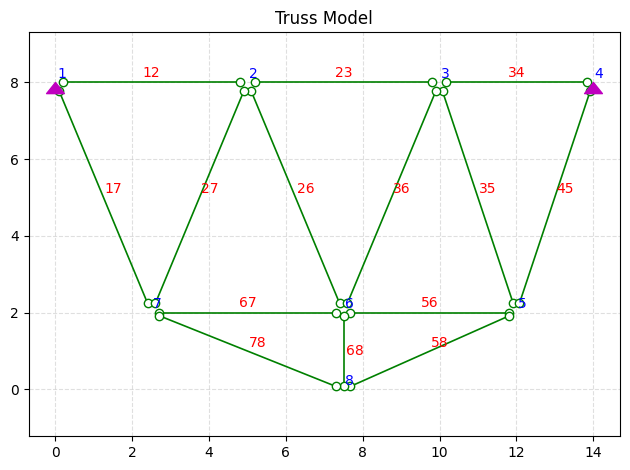

In [2]:
# model defination 
ops.wipe()
ops.model('basic', '-ndm', 2, '-ndf', 2) #ops.model('basic', '-ndm', 2, '-ndf', 2) 
ops.uniaxialMaterial('Elastic', 1, E)    #ops.uniaxialMaterial('Elastic', matTag, E)


# node
ops.node(1, 0.00,8.00)  #ops.node(nodeTag, xCrd, yCrd, zCrd)
ops.node(2, 5.00,8.00)
ops.node(3, 10.00,8.00)
ops.node(4, 14.00,8.00)
ops.node(5, 12.00,2.00)
ops.node(6, 7.50,2.00)
ops.node(7, 2.50,2.00)
ops.node(8, 7.50,0.00)

# element
ops.element('truss', 12, 1, 2, A, 1)  #ops.element('truss', eleTag, iNode, jNode, A, matTag)
ops.element('truss', 23, 2, 3, A, 1)
ops.element('truss', 34, 3, 4, A, 1)
ops.element('truss', 45, 4, 5, A, 1)
ops.element('truss', 56, 5, 6, A, 1)
ops.element('truss', 67, 6, 7, A, 1)
ops.element('truss', 17, 1, 7, A, 1)
ops.element('truss', 26, 2, 6, A, 1)
ops.element('truss', 35, 3, 5, A, 1)
ops.element('truss', 27, 2, 7, A, 1)
ops.element('truss', 36, 3, 6, A, 1)
ops.element('truss', 78, 7, 8, A, 1)
ops.element('truss', 68, 6, 8, A, 1)
ops.element('truss', 58, 5, 8, A, 1)

# fixity 
ops.fix(1, 1, 1) #ops.fix(nodeTag, 1, 1)
ops.fix(4, 1, 1)


# load defination 

ops.timeSeries('Constant', 1) #ops.timeSeries('Constant', timeSeriesTag)
ops.pattern('Plain', 1, 1)
ops.load(2,0,-50)
ops.load(3,0,-50)
ops.load(8,0,-60)
opsv.plot_model(
    node_labels     = 1,
    element_labels  = 1,
)
plt.title('Truss Model')
plt.axis('equal')
plt.grid(True, linestyle='--', alpha=0.4)
plt.tight_layout()
plt.show()

In [3]:
# Analysis 
ops.system('BandGeneral')
ops.numberer('RCM')
ops.constraints('Plain')
ops.integrator('LoadControl', 1)
ops.analysis('Static')
ops.analyze(1)


WARNING analysis Static - no Algorithm yet specified, 
 NewtonRaphson default will be used


0

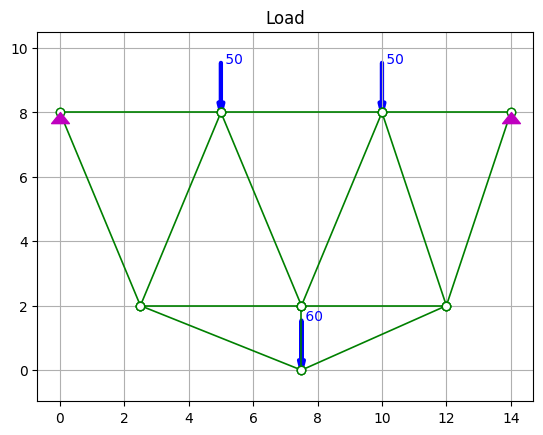

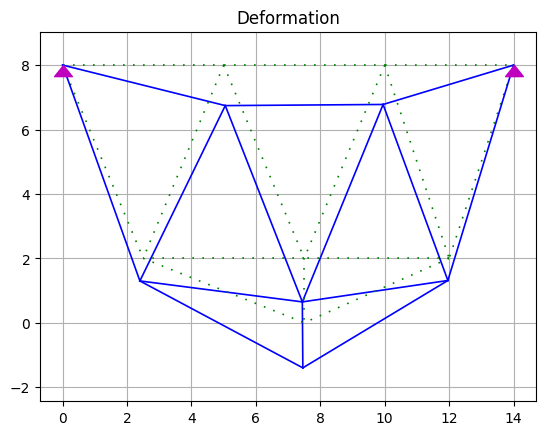

In [4]:
# plot load 

opsv.plot_load(nep=11, sfac=False, fig_wi_he=False, fig_lbrt=False, fmt_model_loads={'color': 'black', 'linestyle': 'solid', 'linewidth': 1.2, 'marker': '', 'markersize': 1}, node_supports=True, truss_node_offset=0, local_axes=False, ax=False,)
plt.title('Load')
plt.grid()

# plot deformation

opsv.plot_defo()
plt.title('Deformation')
plt.grid()
plt.show()


In [5]:
# output

ops.reactions()
r1 = ops.nodeReaction(1,1)
r2 = ops.nodeReaction(1,2)
r3 = ops.nodeReaction(4,1)
r4 = ops.nodeReaction(4,2)

ux = ops.nodeDisp(8,1)
uy = ops.nodeDisp(8,2)

print('horizontal reaction at node 1:', r1)
print('vertical reaction at node 1:', r2)
print('horizontal reaction at node 4:', r3)
print('vertical reaction at node 4:', r4)




print(f"\n── Node Displacements ─────────────────")
print(f"{"Node":<10} {'Ux (m)':>10} {'Uy (m)':>10}")
print("-" * 38)
for i in range(1, 9):
    print(f"{i:<10} {ops.nodeDisp(i,1):>10.4e} {ops.nodeDisp(i,2):>10.4e}")


elem_tags = [12, 23, 34, 45, 56, 67,
             17, 26, 35, 27, 36,
             78, 68, 58]

print(f"\n── Element Axial Forces ─────────────────")
print(f"{'Element':<10} {'Force (N)':>10} {'status':>10}")
print("-" * 40)
for tag in elem_tags:
    force = ops.eleForce(tag)    
    axial = force[0]
    status = "TENSION" if axial > 0 else "COMPRESSION"
    print(f"{tag:<10} {axial:>10.4f} {status:>10}")


horizontal reaction at node 1: -39.388586934050956
vertical reaction at node 1: 74.28571428571425
horizontal reaction at node 4: 39.38858693405099
vertical reaction at node 4: 85.71428571428574

── Node Displacements ─────────────────
Node           Ux (m)     Uy (m)
--------------------------------------
1          0.0000e+00 0.0000e+00
2          4.2181e-08 -1.0814e-06
3          -4.3269e-08 -1.0510e-06
4          0.0000e+00 0.0000e+00
5          -3.3603e-08 -5.9114e-07
6          -4.9793e-08 -1.1627e-06
7          -8.7275e-08 -6.0305e-07
8          -3.6286e-08 -1.2039e-06

── Element Axial Forces ─────────────────
Element     Force (N)     status
----------------------------------------
12            -8.4362 COMPRESSION
23            17.0899    TENSION
34           -10.8172 COMPRESSION
45            28.5714    TENSION
56             3.5980    TENSION
67             7.4962    TENSION
17           -30.9524 COMPRESSION
26            -2.3464 COMPRESSION
35            21.6624    TENSION
